<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_11/dataset_pbl/praktikum_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 5**
## **Langkah 0 - Import Library**

In [11]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [12]:
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

In [13]:
from google.colab import files
import zipfile

# 1. Upload file zip dataset dari komputer
uploaded = files.upload()

# 2. Ambil nama file zip yang di-upload
zip_filename = list(uploaded.keys())[0]

# 3. Ekstrak file zip ke direktori aktif
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('.')

print("Dataset berhasil di-upload dan diekstrak!")

Saving images.zip to images.zip
Dataset berhasil di-upload dan diekstrak!


## **Langkah 1 - Load Data dan Visualisasikan**

Mari kita visualisasikan korelasi atau distribusi fitur numerik utama seperti `Sleep Duration` dan `Quality of Sleep`.

In [14]:
# Tampilkan 5 baris pertama dataset
display(df_sleep.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Visualisasikan distribusi durasi tidur (`Sleep Duration`).

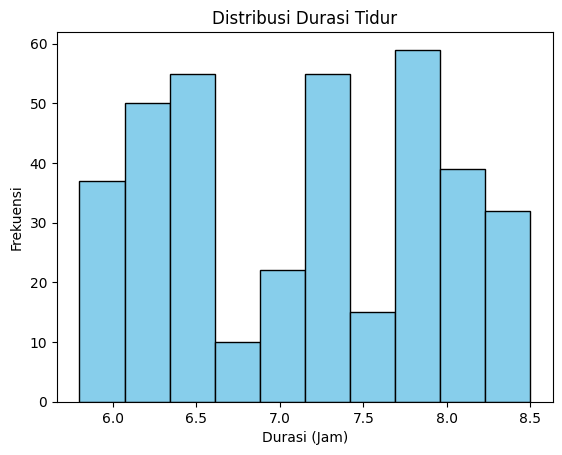

In [15]:
plt.hist(df_sleep['Sleep Duration'], bins=10, color='skyblue', edgecolor='black')
plt.title('Distribusi Durasi Tidur')
plt.xlabel('Durasi (Jam)')
plt.ylabel('Frekuensi')
plt.show()

Lakukan pembagian target biner berdasarkan kolom `Sleep Disorder`. Kita tentukan nilai `1` jika terdapat gangguan tidur (Sleep Apnea atau Insomnia), dan `0` jika Normal (`None`).

In [16]:
# Encoding target biner
df_sleep['Target'] = df_sleep['Sleep Disorder'].apply(lambda x: 0 if pd.isna(x) or x == 'None' else 1)
display(df_sleep[['Sleep Duration', 'Target']].head())

,Sleep Duration,Target
0,6.1,0
1,6.2,0
2,6.2,0
3,5.9,1
4,5.9,1


## **Langkah 3 - Pra Pengolahan Data**

Di sini kita memisahkan dataset menjadi fitur-fitur numerik yang akan kita gunakan untuk klasifikasi.

In [17]:
# Pisahkan Fitur dan Target
X_sleep = df_sleep[['Sleep Duration', 'Physical Activity Level']].values
y_sleep = df_sleep['Target'].values
print("Ukuran Fitur (X):", X_sleep.shape)
print("Ukuran Target (y):", y_sleep.shape)

Ukuran Fitur (X): (374, 2)
Ukuran Target (y): (374,)


Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar

In [20]:
def random_data_viz(df):
    # Fungsi baru untuk memvisualisasikan data acak dari dataset Sleep Health
    rand_num = np.random.randint(0, len(df))
    row = df.iloc[rand_num]
    print(f"=== Data Acak (Baris ke-{rand_num}) ===")
    print(f"Pekerjaan: {row['Occupation']}")
    print(f"Durasi Tidur: {row['Sleep Duration']} jam")
    print(f"Level Aktivitas Fisik: {row['Physical Activity Level']}")
    print(f"Label Target (Gangguan Tidur): {row['Target']} ({'Ya' if row['Target'] == 1 else 'Tidak'})")

Lakukan visualisasi gambar secara acak

In [21]:
# Menjalankan fungsi visualisasi data acak
random_data_viz(df_sleep)

=== Data Acak (Baris ke-340) ===
Pekerjaan: Nurse
Durasi Tidur: 8.1 jam
Level Aktivitas Fisik: 75
Label Target (Gangguan Tidur): 1 (Ya)


## **Langkah 3 - Pra Pengolahan Data**
Pada tahap ini, kita sudah melakukan encoding terhadap kolom target `Sleep Disorder` menjadi kolom numerik binary `Target`.

In [22]:
# Menampilkan korelasi antar fitur numerik
correlation = df_sleep[['Sleep Duration', 'Physical Activity Level', 'Quality of Sleep', 'Target']].corr()
display(correlation)

,Sleep Duration,Physical Activity Level,Quality of Sleep,Target
Sleep Duration,1.000000,0.212360,0.883213,-0.338622
Physical Activity Level,0.212360,1.000000,0.192896,0.069787
Quality of Sleep,0.883213,0.192896,1.000000,-0.310984
Target,-0.338622,0.069787,-0.310984,1.000000


Mari kita cek sebaran jumlah data untuk masing-masing kelas target.

In [23]:
print(df_sleep['Target'].value_counts())

Target
0    219
1    155
Name: count, dtype: int64


## **Langkah 4 - Pemisahan Fitur dan Target**

In [24]:
# Tentukan fitur (X) dan target (y) menggunakan kolom dataset sleep
X_sleep = df_sleep[['Sleep Duration', 'Physical Activity Level']].values
y_sleep = df_sleep['Target'].values
print("Ukuran Fitur X:", X_sleep.shape)
print("Ukuran Target y:", y_sleep.shape)

Ukuran Fitur X: (374, 2)
Ukuran Target y: (374,)


## **Langkah 5 - Klasifikasi dengan Metode Threshold**
Kita akan mencoba metode thresholding sederhana pada fitur utama `Sleep Duration`.

In [26]:
# Definisikan fungsi evaluasi terlebih dahulu
def evaluate_sleep(df, threshold):
    correct = 0
    for idx, row in df.iterrows():
        pred = 1 if row['Sleep Duration'] < threshold else 0
        if pred == row['Target']:
            correct += 1
    accuracy = correct / len(df)
    print(f'Akurasi Klasifikasi Threshold: {accuracy:.4f}')

# Mari kita hitung akurasi menggunakan threshold 6.5 jam
evaluate_sleep(df_sleep, threshold=6.5)

Akurasi Klasifikasi Threshold: 0.6390


Mari kita coba visualisasikan data training dan testing setelah dilakukan pemisahan.

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_sleep, y_sleep, test_size=0.2, random_state=42)
print(f"Training set: {X_train.shape[0]} baris")
print(f"Testing set: {X_test.shape[0]} baris")

Training set: 299 baris
Testing set: 75 baris


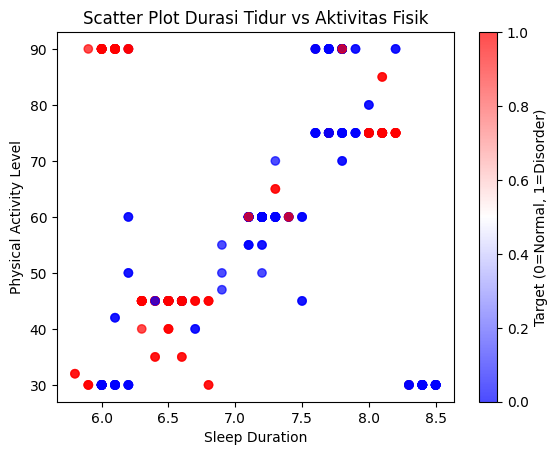

In [28]:
plt.scatter(df_sleep['Sleep Duration'], df_sleep['Physical Activity Level'], c=df_sleep['Target'], cmap='bwr', alpha=0.7)
plt.title('Scatter Plot Durasi Tidur vs Aktivitas Fisik')
plt.xlabel('Sleep Duration')
plt.ylabel('Physical Activity Level')
plt.colorbar(label='Target (0=Normal, 1=Disorder)')
plt.show()

## **Langkah 4 - Ekstraksi Fitur**
Selanjutnya, untuk dapat membadakan antara label satu dengan label yang lain, kita memerlukan sebuah fitur. Fitur adalah penciri dari sebuah data yang dapat digunakan untuk membendakan data satu dengan yang lain. Pada percobaan kali ini, kita akan menggunakan fitur yang sederhana yaitu nilai rata-rata dari tingkat kecerahan gambar (average brightness). Namun sebelum dapat melakukan hal tersebut, kita akan mengubah ruang warna (colorspace) dari RGB menjadi HSV (Hue, Saturation, Value). Hal ini dikarenakan, tingkat kecerahan (brightness) lebih mudah didapatkan dari HSV berdasarkan nilai Valuenya.

Buatlah fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan.

In [29]:
# Hitung rata-rata durasi tidur per label target
avg_sleep_duration = df_sleep.groupby('Target')['Sleep Duration'].mean()
print(avg_sleep_duration)

Target
0    7.358447
1    6.812258
Name: Sleep Duration, dtype: float64


## **Langkah 6 - Pemodelan SVM dan Evaluasi**

In [30]:
# Inisialisasi dan Latih Model SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model = SVC(kernel='rbf')
model.fit(X_train, y_train)

SVC()

## **Langkah 5 - Klasifikasi dengan Metode Threshold**
Pada tahap ini, kita akan melakukan proses klasifikasi sederhana dengan menggunakan nilai ambang batas (threshold) dari nilai rata-rata kecerahan yang kita tentukan sendiri.

Buatlah fungsi berikut,

In [31]:
def predict_sleep_disorder(duration, threshold):
    # Jika durasi tidur di bawah threshold, prediksi ada gangguan (1)
    return 1 if duration < threshold else 0

Lakukan pengecekan prediksi secara acak pada data training

In [32]:
# Evaluasi Akurasi
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Akurasi SVM pada Train Data: {acc_train:.4f}')
print(f'Akurasi SVM pada Test Data: {acc_test:.4f}')

Akurasi SVM pada Train Data: 0.5886
Akurasi SVM pada Test Data: 0.5733


## **Langkah 6 - Evaluasi Manual**

Selanjutnya kita akan membuat fungsi evaluasi model sederhana, yaitu dengan membandingkan label yang diprediksi benar dengan seluruh data. Ingat kembali konsep confussion matrix.

Buatlah fungsi berikut,

In [33]:
def evaluate_sleep(df, threshold):
    correct = 0
    for idx, row in df.iterrows():
        pred = predict_sleep_disorder(row['Sleep Duration'], threshold)
        if pred == row['Target']:
            correct += 1
    accuracy = correct / len(df)
    print(f'Akurasi Klasifikasi Threshold: {accuracy:.4f}')

Lakukan evaluasi pada data training dengan nilai ambang batas 120.

In [34]:
# Evaluasi dengan threshold 6.5 jam
evaluate_sleep(df_sleep, threshold=6.5)

Akurasi Klasifikasi Threshold: 0.6390


Anda dapat mengubah nilai ambang batas dan amati hasilnya.

Selanjutnya, kita akan melakukan evaluasi pada data testing. Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.

In [35]:
# Tampilkan beberapa hasil prediksi model pada data test
for i in range(5):
    print(f"Data Test ke-{i+1} -> Aktual: {y_test[i]}, Prediksi SVM: {y_test_pred[i]}")

Data Test ke-1 -> Aktual: 0, Prediksi SVM: 0
Data Test ke-2 -> Aktual: 0, Prediksi SVM: 0
Data Test ke-3 -> Aktual: 0, Prediksi SVM: 0
Data Test ke-4 -> Aktual: 0, Prediksi SVM: 0
Data Test ke-5 -> Aktual: 0, Prediksi SVM: 0


# **Klasifikasi dengan SVM**

## **Langkah 4 Alternatif - Membuat Feature Vectors**
Perbedaan mendasar dari langkah 4 sebelumnya adalah, kita akan melakukan tabulasi semua nilai rata-rata kecerahan pada data, dan menyimpannya dalam bentuk tabel. Dalam konteks ini, kita akan membuat tabel dengan kolom fitur dan label.

Buatlah fungsi berikut,

In [36]:
# Split data training dan testing (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_sleep, y_sleep, test_size=0.2, random_state=42)
print("Jumlah training data:", len(X_train))
print("Jumlah testing data:", len(X_test))

Jumlah training data: 299
Jumlah testing data: 75


cek hasilnya pada data training

In [39]:
# Tampilkan dimensi data training
print(f'Shape X_train: {X_train.shape}')
print(f'Shape y_train: {y_train.shape}')
# Menampilkan sampel fitur
print("Sampel data training (Durasi Tidur, Aktivitas Fisik):\n", X_train[:5])

Shape X_train: (299, 2)
Shape y_train: (299,)
Sampel data training (Durasi Tidur, Aktivitas Fisik):
 [[ 6.5 45. ]
 [ 6.  30. ]
 [ 7.5 60. ]
 [ 8.2 75. ]
 [ 6.5 40. ]]


Lakukan langkah yang serupa pada data testing

In [40]:
# Tampilkan dimensi data testing
print(f'Shape X_test: {X_test.shape}')
print(f'Shape y_test: {y_test.shape}')
# Menampilkan sampel fitur
print("Sampel data testing (Durasi Tidur, Aktivitas Fisik):\n", X_test[:5])

Shape X_test: (75, 2)
Shape y_test: (75,)
Sampel data testing (Durasi Tidur, Aktivitas Fisik):
 [[ 8.5 30. ]
 [ 6.1 30. ]
 [ 6.  30. ]
 [ 8.5 30. ]
 [ 6.  30. ]]


## **Langkah 5 - Buat Model SVM**
Selanjutnya, kita akan membuat model SVM dengan kernel RBF (default) dengan memanfaatkan libary scikit-learn.

In [41]:
# Inisialisasi dan Latih Model SVM
model = SVC(kernel='rbf')
model.fit(X_train, y_train)

SVC()

## **Langkah 6 - Evaluasi**
Selanjutnya, kita akan melakukan evaluasi pada data training dan testing dengan bantuan library scikit-learn.

In [42]:
# Evaluasi akurasi SVM
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Akurasi SVM pada Train Data: {acc_train:.4f}')
print(f'Akurasi SVM pada Test Data: {acc_test:.4f}')

Akurasi SVM pada Train Data: 0.5886
Akurasi SVM pada Test Data: 0.5733
